# Градиентный бустинг

Третье занятие. В прошлый раз мы разобрали решающие деревья и ансамбли, которые
усредняют независимо обученные модели: бэггинг и случайный лес. Сегодня — вторая
схема ансамблирования, в которой модели строятся **последовательно**, и каждая
следующая исправляет ошибки уже построенной композиции.

План: сначала механика бустинга на синтетических данных, где известен правильный
ответ и видно каждое свойство по отдельности, затем применение к реальной задаче
и сравнение со всеми моделями прошлых занятий.

## 0. Импорт пакетов, загрузка данных

In [1]:
# %pip install -q numpy pandas matplotlib scikit-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 130)
pd.set_option("display.precision", 4)

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

RANDOM_STATE = 42

In [3]:
URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

def load_titanic(url: str = URL) -> pd.DataFrame:
    try:
        return pd.read_csv(url)
    except Exception as e:
        raise RuntimeError(f"Источник недоступен ({type(e).__name__}): {url}") from e

df = load_titanic()
print(f"{len(df)} наблюдений, {df.shape[1]} столбцов")
df.head()

891 наблюдений, 12 столбцов


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
print(df.dtypes.to_frame("тип").join(df.isna().sum().to_frame("пропусков")).to_string())

                 тип  пропусков
PassengerId    int64          0
Survived       int64          0
Pclass         int64          0
Name             str          0
Sex              str          0
Age          float64        177
SibSp          int64          0
Parch          int64          0
Ticket           str          0
Fare         float64          0
Cabin            str        687
Embarked         str          2


## 1. Данные и постановка задачи

### 1.1 Задача

`Survived` — выжил ли пассажир. В отличие от прошлых занятий это **классификация**,
а не регрессия, поэтому меняются и функция потерь, и метрики.

Доля выживших заметно меньше половины, так что доля правильных ответов (accuracy)
у константного прогноза уже высокая, и сама по себе она неинформативна.

In [5]:
y = df["Survived"]
print(f"выжили: {y.sum()} из {len(y)} ({y.mean():.4f})")
print(f"accuracy константного прогноза «не выжил»: {1 - y.mean():.4f}")

выжили: 342 из 891 (0.3838)
accuracy константного прогноза «не выжил»: 0.6162


Поэтому основной метрикой возьмём **ROC-AUC**. Её удобно понимать так.

Составим все пары «выживший — невыживший» и для каждой проверим: спрогнозировала ли модель
выжившему большую вер-ть, чем невыжившему? **AUC — это доля пар, где ответ «да».**

In [6]:
from sklearn.metrics import roc_auc_score

rng = np.random.default_rng(RANDOM_STATE)
score = rng.random(len(y))                    
pos, neg = score[y == 1], score[y == 0]

print(f"пар «выживший — невыживший»: {len(pos)} x {len(neg)} = {len(pos) * len(neg)}")
print(f"доля верно упорядоченных пар: {(pos[:, None] > neg[None, :]).mean():.6f}")
print(f"roc_auc_score:               {roc_auc_score(y, score):.6f}")

пар «выживший — невыживший»: 342 x 549 = 187758
доля верно упорядоченных пар: 0.472086
roc_auc_score:               0.472086


- AUC $=1$ — все выжившие стоят выше всех невыживших, то есть алгоритм правильно ранжирует все объекты по вероятностям; 
- AUC $=0.5$ — порядок угадан примерно в половине пар, то есть не лучше монетки (ровно это и дал случайный прогноз выше); 

Порог прогнозирования не нужен, потому что метрика смотрит только на порядок. Accuracy также будем приводить рядом.

Что значит порог: после того, как алгоритм выдал прогноз вероятности $P(y\mid x)$ нужно выдать прогноз конкретного класса. Если $y\in \{0, 1\}$, то можно записать систему:

\begin{equation}
\left\{
\begin{aligned}
1, \text{если} \,\,P(y\mid x) \geq c\\
0, \text{если} \,\,P(y\mid x) < c
\end{aligned}
\right.
\end{equation}

$c$ и есть порог. Он подбирается под конкретную метрику, если конечно она от него зависит.

### 1.2 Признаки

`PassengerId`, `Name`, `Ticket` — идентификаторы, `Cabin` заполнена лишь у 204
пассажиров из 891. Остаётся четыре числовых признака и три категориальных.

In [7]:
NUM = ["Age", "Fare", "SibSp", "Parch"]
CAT = ["Pclass", "Sex", "Embarked"]

X = df[NUM + CAT].copy()
print(X.describe().T.to_string())
print()
for c in CAT:
    print(f"{c}: {X[c].value_counts(dropna=False).to_dict()}")

        count     mean      std   min      25%      50%   75%       max
Age     714.0  29.6991  14.5265  0.42  20.1250  28.0000  38.0   80.0000
Fare    891.0  32.2042  49.6934  0.00   7.9104  14.4542  31.0  512.3292
SibSp   891.0   0.5230   1.1027  0.00   0.0000   0.0000   1.0    8.0000
Parch   891.0   0.3816   0.8061  0.00   0.0000   0.0000   0.0    6.0000
Pclass  891.0   2.3086   0.8361  1.00   2.0000   3.0000   3.0    3.0000

Pclass: {3: 491, 1: 216, 2: 184}
Sex: {'male': 577, 'female': 314}
Embarked: {'S': 644, 'C': 168, 'Q': 77, nan: 2}


### 1.3 Дубликаты

На прошлом датасете мы удаляли повторяющиеся строки: одинаковые одиннадцать химических
измерений почти наверняка означали один и тот же образец вина, измеренный дважды.

Здесь ситуация другая. Совпадение по данным признакам вполне вероятно для разных людей.

In [8]:
mask = X.duplicated(keep=False)
twins = df[mask].copy()
twins["группа"] = X[mask].groupby(list(X.columns), dropna=False).ngroup()
conflict = twins.groupby("группа")["Survived"].nunique()

print(f"строк, у которых есть полный двойник по признакам: {mask.sum()}")
print(f"таких групп: {twins['группа'].nunique()}, из них с разным исходом: {(conflict > 1).sum()}")
print()
shown = conflict[conflict > 1].index[:3]
print(twins[twins["группа"].isin(shown)]
      [["группа", "Name", "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked", "Survived"]]
      .sort_values("группа").to_string(index=False))

строк, у которых есть полный двойник по признакам: 193
таких групп: 66, из них с разным исходом: 16

 группа                            Name  Pclass  Sex  Age  SibSp  Parch  Fare Embarked  Survived
      1  Sunderland, Mr. Victor Francis       3 male 16.0      0      0  8.05        S         1
      1    Rush, Mr. Alfred George John       3 male 16.0      0      0  8.05        S         0
      5      Dorking, Mr. Edward Arthur       3 male 19.0      0      0  8.05        S         1
      5      Beavan, Mr. William Thomas       3 male 19.0      0      0  8.05        S         0
      6       Mellors, Mr. William John       2 male 19.0      0      0 10.50        S         1
      6 Pengelly, Mr. Frederick William       2 male 19.0      0      0 10.50        S         0


Имена разные — это разные пассажиры, а их признаки полностью совпадают, поэтому дубликаты здесь оставим.

Важнее тут другое. Объекты, неразличимые по признакам, имеют разные значения целевой переменной `Survived`. Поэтому их не различит
никакая модель, как её ни усложняй.

### 1.4 Разбиение и препроцессинг

Схему берём ту, к которой пришли в конце прошлого занятия: гиперпараметры подбираются
кросс-валидацией на обучающей части, тест используется один раз.

То, чего не было в задаче с регрессией — **стратификация**. Классы несбалансированы, и при
случайном разбиении доля выживших в фолдах будет гулять, добавляя разброса в оценку.
`stratify=y` и `StratifiedKFold` сохраняют пропорцию классов в каждой части при разбиениях выборки.

In [9]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f"train_full {len(X_train_full)} | test {len(X_test)}")
print(f"доля выживших: train_full {y_train_full.mean():.4f}, test {y_test.mean():.4f}")

train_full 712 | test 179
доля выживших: train_full 0.3834, test 0.3855


Пропуски в `Age` (177 штук) надо чем-то заполнить, а категориальные признаки —
закодировать.

Если заполнить пропуски медианой по всем данным, а потом разбить выборку, то медиана
окажется посчитанной в том числе по тесту. Поэтому препроцессинг собирается в `Pipeline` вместе с моделью —
тогда при кросс-валидации медиана и список категорий считаются заново внутри каждого
обучающего фолда.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer # Заполнение пропусков
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def make_prep(scale: bool = False) -> ColumnTransformer:
    """scale=True нужен моделям, чувствительным к масштабу: kNN и логрегрессии."""
    num_steps = [("imp", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("sc", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), NUM),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(drop="first", handle_unknown="ignore"))]), CAT),
    ])


def make_pipe(model, scale: bool = False) -> Pipeline:
    return Pipeline([("prep", make_prep(scale)), ("model", model)])


FEATURES = list(make_prep().fit(X_train_full).get_feature_names_out())
print(f"{len(FEATURES)} признаков после кодирования:")
print(FEATURES)

9 признаков после кодирования:
['num__Age', 'num__Fare', 'num__SibSp', 'num__Parch', 'cat__Pclass_2', 'cat__Pclass_3', 'cat__Sex_male', 'cat__Embarked_Q', 'cat__Embarked_S']


### 1.5 Бейзлайны

Три модели с прошлых занятий с настройками по умолчанию.

Логистическая регрессия - линейная модель для задачи классификации. Ее формулировка совпадает с линейной регрессией, только в выходу применяется сигмоида $\sigma(x)$ - функция, которая перевод вещественные числа на отрезок от 0 до 1, то есть в вероятности:

$$
P(y=1\mid x)=\frac{1}{1 + \exp(-\left< w, x \right>)}=\sigma(\left< w, x \right>)
$$

При этом в качестве функции потерь выступает функция правдоподобия со знаком минус:

$$
L(y, a(x)) = -\sum_{i=1}^n\left(y\cdot a(x) + (1-y)\cdot (1 - a(x))\right),
$$

где $a(x)$ - модель, которая выдает вероятности, логистическая регрессия как раз таки сюда подходит.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier


def cv_score(model, scoring="roc_auc"):
    return cross_val_score(model, X_train_full, y_train_full, cv=skf,
                           scoring=scoring, n_jobs=-1)


baselines = {
    "логистическая регрессия": (LogisticRegression(max_iter=2000), True),
    "решающее дерево":         (DecisionTreeClassifier(random_state=RANDOM_STATE), False),
    "случайный лес":           (RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), False),
}

rows = []
for name, (m, sc) in baselines.items():
    auc, acc = cv_score(make_pipe(m, sc)), cv_score(make_pipe(m, sc), "accuracy")
    rows.append({"модель": name, "CV AUC": auc.mean(), "CV std": auc.std(),
                 "CV accuracy": acc.mean()})

pd.DataFrame(rows).set_index("модель").round(4)

,CV AUC,CV std,CV accuracy
модель,,,
логистическая регрессия,0.8526,0.0217,0.8020
решающее дерево,0.7563,0.0176,0.7669
случайный лес,0.8629,0.0127,0.8048


## 2. Механика бустинга

В этом разделе обучаемся на синтетических данных: так будет известна истинная зависимость целевой переменной от признаков.

### 2.1 Аддитивная модель

Композиция строится как сумма базовых моделей:

$$a_M(x) = \sum_{m=1}^{M} \gamma_m\, b_m(x), \qquad b_m \in \mathcal{A},$$

где $\mathcal{A}$ - некоторое фиксированное семейство алгоритмов, например, решающие деревья.

Модели строятся **последовательно**, и каждая следующая
обучается с учётом того, что уже построено. Формально на шаге $m$ композиция
$a_{m-1}$ считается зафиксированной, и подбирается только очередное слагаемое:

$$(\gamma_m, b_m) = \arg\min_{\gamma,\, b}\;
\sum_{i=1}^{n} L\big(y_i,\; a_{m-1}(x_i) + \gamma\, b(x_i)\big).$$

Это жадная схема: ранее построенные слагаемые не пересматриваются.

### 2.2 Квадратичная потеря: обучение на остатках

Возьмём $L(y, z) = (y - z)^2$ и подставим в задачу выше:

$$\sum_{i=1}^{n}\big(\underbrace{y_i - a_{m-1}(x_i)}_{s^{(m)}_i} - \gamma b(x_i)\big)^2
= \sum_{i=1}^{n}\big(s_i^{(m)} - \gamma b(x_i)\big)^2,
\qquad s_i^{(m)} = y_i - a_{m-1}(x_i).$$

Справа — обычная задача регрессии, в которой целевой переменной служит **остаток**
текущей композиции. То есть очередная базовая модель обучается предсказывать,
насколько и в какую сторону композиция ошибается.

Проверим это на одномерной задаче с известной $f(x)=\sin(1.5 x)+0.25x$.

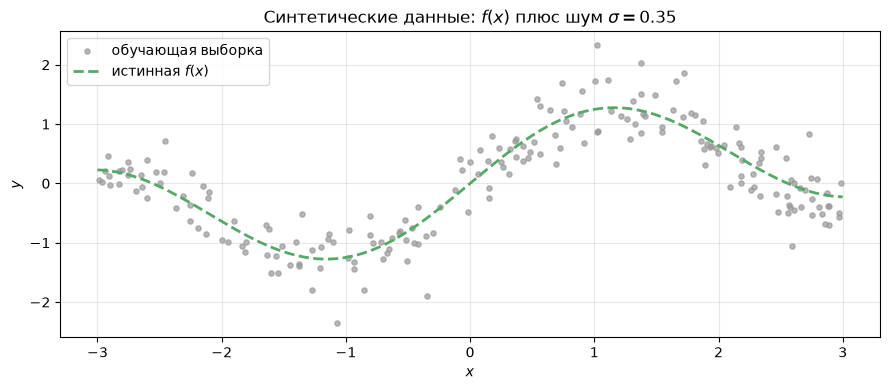

In [12]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error

F_TRUE = lambda x: np.sin(1.5 * x) + 0.25 * x
NOISE = 0.35


def make_reg(n=200, noise=NOISE, seed=0):
    rng = np.random.default_rng(seed)
    x = rng.uniform(-3, 3, n)
    return x.reshape(-1, 1), F_TRUE(x) + rng.normal(0, noise, n)


X_syn, y_syn = make_reg(200, seed=0)
X_syn_te, y_syn_te = make_reg(2000, seed=1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(X_syn, y_syn, s=14, color="#999999", alpha=0.7, label="обучающая выборка")
xx = np.linspace(-3, 3, 400)
ax.plot(xx, F_TRUE(xx), color="#55A868", lw=2, ls="--", label="истинная $f(x)$")
ax.set_xlabel("$x$"); ax.set_ylabel("$y$")
ax.set_title(f"Синтетические данные: $f(x)$ плюс шум $\\sigma = {NOISE}$")
ax.legend()
plt.tight_layout(); plt.show()

Руками реализуем то, что записано выше. Веса каждой базовой модели в композиции зафиксируем $\gamma=0.3$.

In [13]:
def boost_squared(Xtr, ytr, Xs, depth=2, lr=0.3, M=300):
    """Возвращает предсказания композиции на Xs после каждой итерации."""
    f_tr = np.full(len(ytr), ytr.mean())
    f_s = np.full(len(Xs), ytr.mean())
    path = []
    for _ in range(M):
        resid = ytr - f_tr
        b = DecisionTreeRegressor(max_depth=depth, random_state=RANDOM_STATE).fit(Xtr, resid) # Каждый шаг учит остатки на исходных признаках
        f_tr = f_tr + lr * b.predict(Xtr)
        f_s = f_s + lr * b.predict(Xs)
        path.append(f_s.copy())
    return np.array(path)


DEPTH, LR = 2, 0.3
path_tr = boost_squared(X_syn, y_syn, X_syn, DEPTH, LR, 300)
path_te = boost_squared(X_syn, y_syn, X_syn_te, DEPTH, LR, 300)

for m in (1, 2, 3, 5, 10, 30, 100, 300):
    print(f"M={m:4d}   train MSE {mean_squared_error(y_syn, path_tr[m-1]):.4f}"
          f"   test MSE {mean_squared_error(y_syn_te, path_te[m-1]):.4f}")

M=   1   train MSE 0.4754   test MSE 0.4832
M=   2   train MSE 0.3235   test MSE 0.3275
M=   3   train MSE 0.2350   test MSE 0.2431
M=   5   train MSE 0.1531   test MSE 0.1687
M=  10   train MSE 0.1045   test MSE 0.1353
M=  30   train MSE 0.0720   test MSE 0.1414
M= 100   train MSE 0.0308   test MSE 0.1687
M= 300   train MSE 0.0037   test MSE 0.2151


Посмотрим на процесс по шагам. Сверху — текущая композиция $a_M$, снизу — остаток,
который приближает очередное дерево $b_m$.

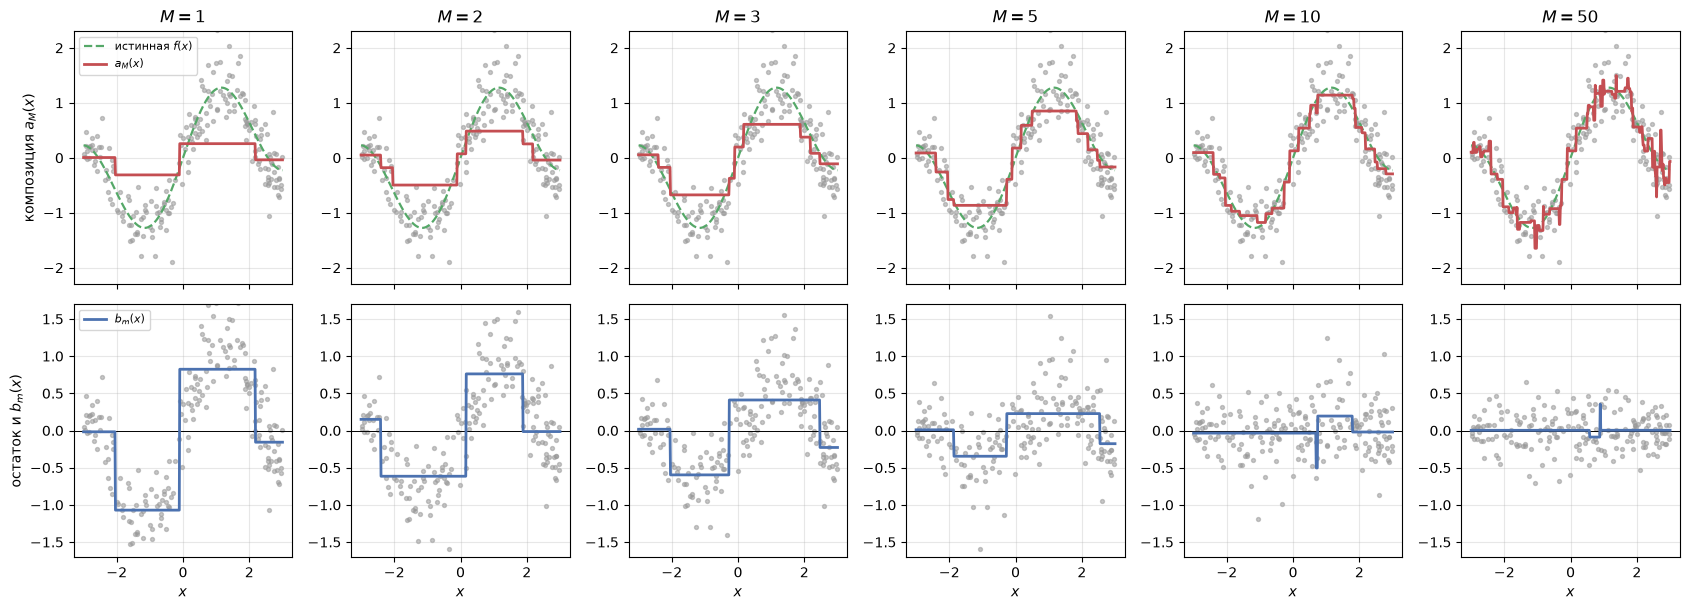

In [14]:
STEPS = (1, 2, 3, 5, 10, 50)
grid = np.linspace(-3, 3, 400).reshape(-1, 1)

f_tr = np.full(len(y_syn), y_syn.mean())
f_gr = np.full(len(grid), y_syn.mean())
comp, step_tree = {}, {}
for m in range(1, max(STEPS) + 1):
    resid = y_syn - f_tr
    b = DecisionTreeRegressor(max_depth=DEPTH, random_state=RANDOM_STATE).fit(X_syn, resid)
    if m in STEPS:
        step_tree[m] = (resid.copy(), b.predict(grid)) # Сохраняем остатки и предсказания дерева с шага m
    f_tr = f_tr + LR * b.predict(X_syn)
    f_gr = f_gr + LR * b.predict(grid)
    if m in STEPS:
        comp[m] = f_gr.copy() # Сохраняем предсказания композиции с шага m

fig, axes = plt.subplots(2, len(STEPS), figsize=(17, 6.2), sharex=True)
for j, m in enumerate(STEPS):
    a = axes[0, j]
    a.scatter(X_syn.ravel(), y_syn, s=8, color="#999999", alpha=0.55)
    a.plot(grid.ravel(), F_TRUE(grid.ravel()), color="#55A868", lw=1.6, ls="--")
    a.plot(grid.ravel(), comp[m], color="#C44E52", lw=2.0)
    a.set_title(f"$M = {m}$"); a.set_ylim(-2.3, 2.3)
    if j == 0:
        a.set_ylabel("композиция $a_M(x)$")

    c = axes[1, j]
    resid, pred = step_tree[m]
    c.scatter(X_syn.ravel(), resid, s=8, color="#999999", alpha=0.55)
    c.axhline(0, color="black", lw=0.7)
    c.plot(grid.ravel(), pred, color="#4C72B0", lw=2.0)
    c.set_ylim(-1.7, 1.7); c.set_xlabel("$x$")
    if j == 0:
        c.set_ylabel("остаток и $b_m(x)$")

axes[0, 0].plot([], [], color="#55A868", ls="--", lw=1.6, label="истинная $f(x)$")
axes[0, 0].plot([], [], color="#C44E52", lw=2.0, label="$a_M(x)$")
axes[0, 0].legend(fontsize=8, loc="upper left")
axes[1, 0].plot([], [], color="#4C72B0", lw=2.0, label="$b_m(x)$")
axes[1, 0].legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

На первой итерации остаток повторяет форму зависимости,
к десятой он почти бесструктурный, к пятидесятой композиция начинает воспроизводить
отдельные точки, из-за чего красная линия начинает подгоняться под конкретные точки.

Одно дерево глубины 2 даёт максимум 4 области в пространстве признаков, но сумма из пятидесяти таких деревьев уже способна
описывать гладкую кривую.

### 2.3 Общий случай: градиентный бустинг

Остатки — удобное, но частное явление: они возникли именно из квадратичной потери $L(y, z)=(y-z)^2$.
Для произвольной $L$ рассуждают так.

Обозначим через $z_i = a(x_i)$ значения композиции на обучающих объектах. Суммарные
потери $\sum_i L(y_i, z_i)$ — обычная функция $n$ переменных, и её можно уменьшать
градиентным спуском. Антиградиент показывает, куда сдвинуть каждое $z_i$:

$$g_i^{(m)} = -\left.\frac{\partial L(y_i,\, z)}{\partial z}\right|_{z\,=\,a_{m-1}(x_i)}.$$

Сложность в том, что вектор $g^{(m)}$ задан только в точках обучающей выборки,
а нам нужна функция, определённая везде. Поэтому очередная базовая модель обучается
**приближать антиградиент**:

$$b_m = \arg\min_{b \in \mathcal{B}} \sum_{i=1}^{n}\big(g_i^{(m)} - b(x_i)\big)^2.$$

Отсюда и название: это градиентный спуск, только шаг делается не в пространстве
параметров, а в пространстве функций, и каждый шаг приходится приближать элементом
из $\mathcal{B}$.

Для квадратичной потери $\partial L / \partial z = -2(y - z)$, то есть
$g_i^{(m)} = 2 s_i^{(m)}$ — с точностью до множителя это остаток, и мы возвращаемся
к разделу 2.2.

Алгоритм целиком:

> **boost**(выборка, число итераций $M$, темп $\eta$):
> 1. $a_0(x) = \arg\min_{c} \sum_i L(y_i, c)$ — оптимальная константа;
> 2. для $m = 1, \dots, M$:
>    1. посчитать антиградиент $g_i^{(m)}$ в текущих предсказаниях;
>    2. обучить $b_m$ приближать $g^{(m)}$ по квадратичной ошибке;
>    3. подобрать $\gamma_m$;
>    4. $a_m(x) = a_{m-1}(x) + \eta\, \gamma_m\, b_m(x)$.

Два замечания. Базовая модель всегда решает задачу **регрессии**, даже если исходная
задача — классификация: приближается вещественный вектор антиградиента. И появился
множитель $\eta$ — темп обучения, о нём следующий раздел.

Сверим ручную реализацию со `sklearn`.

In [15]:
from sklearn.ensemble import GradientBoostingRegressor

gbr = GradientBoostingRegressor(max_depth=DEPTH, learning_rate=LR, n_estimators=100,
                                random_state=RANDOM_STATE).fit(X_syn, y_syn)

print(f"sklearn:  test MSE {mean_squared_error(y_syn_te, gbr.predict(X_syn_te)):.6f}")
print(f"вручную:  test MSE {mean_squared_error(y_syn_te, path_te[99]):.6f}")

sklearn:  test MSE 0.168697
вручную:  test MSE 0.168697


### 2.4 Темп обучения

Множитель $\eta$ укорачивает каждый шаг:

$$a_m(x) = a_{m-1}(x) + \eta\, \gamma_m b_m(x).$$

При $\eta = 1$ композиция движется к обучающей выборке максимально быстро и так же
быстро её запоминает. Меньшие значения заставляют делать больше итераций, но каждая
отдельная ошибка базовой модели вносит меньший вклад.

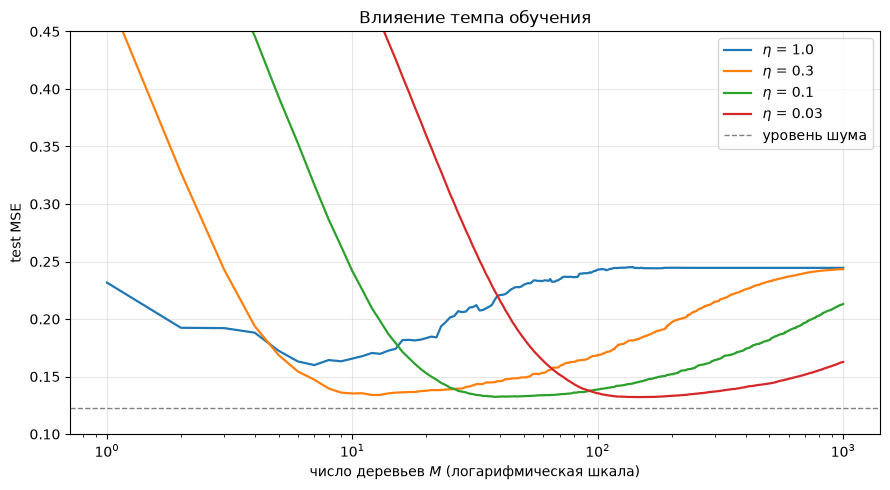

eta= 1.00  минимум 0.1600 на итерации    7   |  на M=100 0.2430   на M=1000 0.2445
eta= 0.30  минимум 0.1340 на итерации   12   |  на M=100 0.1687   на M=1000 0.2434
eta= 0.10  минимум 0.1323 на итерации   38   |  на M=100 0.1387   на M=1000 0.2131
eta= 0.03  минимум 0.1321 на итерации  150   |  на M=100 0.1354   на M=1000 0.1627


In [16]:
rates = (1.0, 0.3, 0.1, 0.03)
M_MAX = 1000
curves = {}
for lr in rates:
    p = boost_squared(X_syn, y_syn, X_syn_te, DEPTH, lr, M_MAX)
    curves[lr] = np.array([mean_squared_error(y_syn_te, q) for q in p]) # Тут собираем MSE для разного кол-ва базовых алгоритмов в композиции

fig, ax = plt.subplots(figsize=(9, 5))
for lr in rates:
    ax.plot(np.arange(1, M_MAX + 1), curves[lr], lw=1.6, label=f"$\\eta$ = {lr}")
ax.axhline(NOISE ** 2, color="gray", ls="--", lw=1, label="уровень шума")
ax.set_xscale("log"); ax.set_xlabel("число деревьев $M$ (логарифмическая шкала)")
ax.set_ylabel("test MSE"); ax.set_ylim(0.10, 0.45)
ax.set_title("Влияение темпа обучения")
ax.legend()
plt.tight_layout(); plt.show()

for lr in rates:
    c = curves[lr]
    print(f"eta={lr:5.2f}  минимум {c.min():.4f} на итерации {int(c.argmin())+1:4d}"
          f"   |  на M=100 {c[99]:.4f}   на M={M_MAX} {c[-1]:.4f}")

Чем меньше $\eta$, тем позже минимум и тем он ниже, но выигрыш быстро насыщается:
между $\eta = 0.1$ и $\eta = 0.03$ разница в четвёртом знаке, а деревьев нужно
вчетверо больше. Если берем 1000 деревьев, то выводы подтверждаются.

Основной вывод: $\eta$ и $M$ — не независимые параметры. Уменьшив темп вдвое,
нужно примерно вдвое увеличить число итераций. Подбирать их по отдельности бессмысленно.

### 2.5 Число итераций

У бэггинга добавление моделей не вредит: с ростом $B$ дисперсия среднего падает,
а смещение не меняется, поэтому лишних деревьев в лесу не бывает.

У бустинга не так. Каждая итерация уменьшает ошибку **на обучающей выборке**,
и рано или поздно композиция начинает приближать шум.

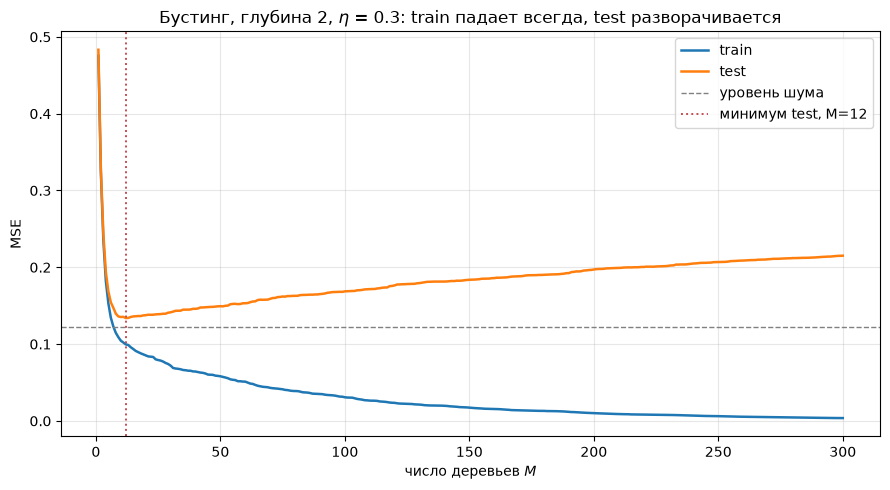

минимум test MSE 0.1340 на M=12
при M=300: train 0.0037, test 0.2151


In [17]:
tr_curve = np.array([mean_squared_error(y_syn, q) for q in path_tr])
te_curve = np.array([mean_squared_error(y_syn_te, q) for q in path_te])
best_m = int(te_curve.argmin()) + 1

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(np.arange(1, 301), tr_curve, lw=1.8, label="train")
ax.plot(np.arange(1, 301), te_curve, lw=1.8, label="test")
ax.axhline(NOISE ** 2, color="gray", ls="--", lw=1, label="уровень шума")
ax.axvline(best_m, color="#C44E52", ls=":", lw=1.4, label=f"минимум test, M={best_m}")
ax.set_xlabel("число деревьев $M$"); ax.set_ylabel("MSE")
ax.set_title(f"Бустинг, глубина {DEPTH}, $\\eta$ = {LR}: train падает всегда, test разворачивается")
ax.legend()
plt.tight_layout(); plt.show()

print(f"минимум test MSE {te_curve.min():.4f} на M={best_m}")
print(f"при M=300: train {tr_curve[-1]:.4f}, test {te_curve[-1]:.4f}")

Train-кривая уходит много ниже уровня шума, test разворачивается и начинает расти.

### 2.6 Сложность базовой модели

В случайном лесу деревья растят без ограничений: усреднение гасит дисперсию,
а смещение глубокого дерева и так мало. У бустинга требование противоположное.

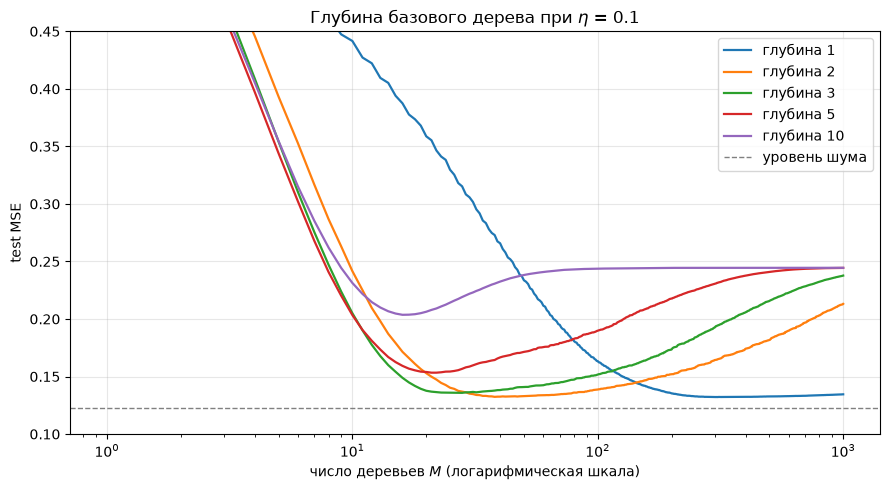

глубина  1:  минимум 0.1321 на M= 301   |  на M=1000 0.1345
глубина  2:  минимум 0.1323 на M=  38   |  на M=1000 0.2131
глубина  3:  минимум 0.1358 на M=  28   |  на M=1000 0.2377
глубина  5:  минимум 0.1533 на M=  21   |  на M=1000 0.2444
глубина 10:  минимум 0.2036 на M=  16   |  на M=1000 0.2445


In [18]:
depths = (1, 2, 3, 5, 10)
M_D = 1000
dep_curves = {}
for d in depths:
    p = boost_squared(X_syn, y_syn, X_syn_te, d, 0.1, M_D)
    dep_curves[d] = np.array([mean_squared_error(y_syn_te, q) for q in p])

fig, ax = plt.subplots(figsize=(9, 5))
for d in depths:
    ax.plot(np.arange(1, M_D + 1), dep_curves[d], lw=1.6, label=f"глубина {d}")
ax.axhline(NOISE ** 2, color="gray", ls="--", lw=1, label="уровень шума")
ax.set_xscale("log"); ax.set_xlabel("число деревьев $M$ (логарифмическая шкала)")
ax.set_ylabel("test MSE"); ax.set_ylim(0.10, 0.45)
ax.set_title("Глубина базового дерева при $\\eta$ = 0.1")
ax.legend()
plt.tight_layout(); plt.show()

for d in depths:
    c = dep_curves[d]
    print(f"глубина {d:2d}:  минимум {c.min():.4f} на M={int(c.argmin())+1:4d}"
          f"   |  на M={M_D} {c[-1]:.4f}")

Чем глубже базовое дерево, тем раньше минимум и тем он хуже. Пни (деревья в одним разбиением - глубина 1) идут к минимуму
дольше всех, но приходят к лучшему значению и почти не деградируют; деревья глубины
10 проходят минимум за полтора десятка итераций и дальше только портятся.

Причина: бустинг сам наращивает сложность — $M$ деревьев глубины $d$ дают до
$M \cdot 2^d$ областей. Если базовая модель уже сложная, композиция переобучается
за несколько шагов.

### 2.7 Выбросы и выбор функции потерь

Объект, на котором композиция ошибается сильно, даёт большой остаток, и следующее
дерево занимается в первую очередь им. Если это выброс, бустинг будет настойчиво
подгонять ошибку. Насколько — зависит от функции потерь: квадратичная растёт как
$a^2$, абсолютная как $|a|$, потеря [Хубера](https://en.wikipedia.org/wiki/Huber_loss) ведёт себя как квадратичная вблизи нуля
и как абсолютная на хвостах.

In [19]:
rng = np.random.default_rng(7)
y_out = y_syn.copy()
y_out[rng.choice(len(y_out), 8, replace=False)] += 8.0      # 8 выбросов из 200

rows = []
for loss in ("squared_error", "absolute_error", "huber"):
    kw = dict(loss=loss, max_depth=2, learning_rate=0.1, n_estimators=300,
              random_state=RANDOM_STATE)
    clean = GradientBoostingRegressor(**kw).fit(X_syn, y_syn)
    dirty = GradientBoostingRegressor(**kw).fit(X_syn, y_out)
    rows.append({"функция потерь": loss,
                 "без выбросов": mean_squared_error(y_syn_te, clean.predict(X_syn_te)),
                 "с выбросами": mean_squared_error(y_syn_te, dirty.predict(X_syn_te))})

losses = pd.DataFrame(rows).set_index("функция потерь")
losses.round(4)

,без выбросов,с выбросами
функция потерь,,
squared_error,0.1643,1.9253
absolute_error,0.1415,0.1437
huber,0.1600,0.3938


Восемь испорченных объектов из двухсот сильно ухудшают квадратичную потерю, а абсолютная их практически не замечает. Параметр `loss` — это не
настройка оптимизатора, а решение о том, какие ошибки мы считаем допустимыми или недопустимыми, на какие обращаем внимание.

## 3. Бустинг для классификации

Алгоритм из раздела 2.3 работает без изменений: нужно лишь взять подходящую функцию потерь
и посчитать её производную.

### 3.1 Логистическая потеря

Композиция предсказывает не вероятность, а **логит** — величину на всей числовой
прямой, которая переводится в вероятность сигмоидой (аналогия с $\left< w, x\right>$ в логистической регрессии):

$$\hat{p}(x) = \sigma\big(a(x)\big) = \frac{1}{1 + e^{-a(x)}}.$$

Так удобнее: складывать деревья можно свободно, не следя за тем, чтобы сумма
оставалась в отрезке $[0, 1]$. Функция потерь — логистическая:

$$L(y, z) = -y \log \sigma(z) - (1 - y) \log\big(1 - \sigma(z)\big).$$

Её производная считается в одну строку, если вспомнить, что
$\sigma'(z) = \sigma(z)\big(1 - \sigma(z)\big)$:

$$\frac{\partial L}{\partial z}
= -y\big(1 - \sigma(z)\big) + (1 - y)\,\sigma(z) = \sigma(z) - y.$$

Значит, антиградиент равен

$$g_i = y_i - \hat{p}_i.$$

То есть очередное дерево предсказывает, **насколько композиция недооценила
вероятность**. Для объекта класса 1 с прогнозом 0.9 остаётся 0.1, а с прогнозом
0.2 — целых 0.8, и внимание следующего дерева достанется ему.

Начальное приближение — оптимальная константа, то есть логит доли положительного
класса: $a_0 = \log\frac{\bar{y}}{1 - \bar{y}}$.

### 3.2 Шаг в листе

В листе дерева $b_m$ стоит среднее значений $g_i = y_i - \hat{p}_i$, то есть
**средняя нехватка вероятности** по объектам этого листа. Но прибавляем мы её
не к вероятности, а к логиту, а связь между ними нелинейна.

Сдвиг логита на $\gamma$ меняет вероятность примерно на

$$\Delta \hat{p} \;\approx\; \gamma \cdot \sigma'(z)
= \gamma \cdot \hat{p}\,(1 - \hat{p}).$$

Множитель $\hat{p}(1-\hat{p})$ — это крутизна сигмоиды. При $\hat{p} = 0.5$ она
максимальна, и логит достаточно подвинуть чуть-чуть. У краёв сигмоида почти плоская,
и тот же сдвиг логита не меняет почти ничего.

Значит, чтобы вероятность сдвинулась на нужные нам $g$, логит надо подвинуть не на
$g$, а на $g$, делённое на крутизну. Для листа $R$:

$$\gamma_R = \frac{\sum_{i \in R} g_i}
{\sum_{i \in R} \hat{p}_i\,(1 - \hat{p}_i)}.$$

Реализуем оба варианта — простое среднее антиградиента и пересчёт через крутизну — и сравним
со `sklearn`.

In [20]:
from sklearn.metrics import log_loss, roc_auc_score, accuracy_score
from sklearn.ensemble import GradientBoostingClassifier

sigmoid = lambda z: 1.0 / (1.0 + np.exp(-z))


def make_clf(n=400, seed=0):
    """Класс 1 — снаружи круга, класс 0 — внутри; граница размыта шумом."""
    rng = np.random.default_rng(seed)
    Xs = rng.uniform(-3, 3, (n, 2))
    p = sigmoid(1.6 * (Xs[:, 0] ** 2 + Xs[:, 1] ** 2 - 3.2))
    return Xs, rng.binomial(1, p)


def boost_logloss(Xtr, ytr, Xs, depth=2, lr=0.3, M=100, newton=True):
    p0 = ytr.mean()
    f_tr = np.full(len(ytr), np.log(p0 / (1 - p0)))
    f_s = np.full(len(Xs), np.log(p0 / (1 - p0)))
    path = []
    for _ in range(M):
        p_hat = sigmoid(f_tr)
        g = ytr - p_hat   # антиградиент
        b = DecisionTreeRegressor(max_depth=depth, random_state=RANDOM_STATE).fit(Xtr, g)
        if newton:
            h = p_hat * (1 - p_hat)
            leaf = b.apply(Xtr)
            gamma = {L: g[leaf == L].sum() / max(h[leaf == L].sum(), 1e-12)
                     for L in np.unique(leaf)} # В каждом листе делаем поправку
            upd_tr = np.array([gamma[L] for L in leaf])
            upd_s = np.array([gamma[L] for L in b.apply(Xs)])
        else:
            upd_tr, upd_s = b.predict(Xtr), b.predict(Xs)
        f_tr = f_tr + lr * upd_tr
        f_s = f_s + lr * upd_s
        path.append(f_s.copy())
    return np.array(path)


X_c, y_c = make_clf(400, seed=0)
X_c_te, y_c_te = make_clf(4000, seed=1)

rows = []
for newton in (False, True):
    p = sigmoid(boost_logloss(X_c, y_c, X_c_te, 2, 0.3, 100, newton=newton)[-1])
    rows.append({"реализация": f"вручную, newton={newton}", "logloss": log_loss(y_c_te, p),
                 "AUC": roc_auc_score(y_c_te, p), "accuracy": accuracy_score(y_c_te, p > 0.5)})

gbc = GradientBoostingClassifier(max_depth=2, learning_rate=0.3, n_estimators=100,
                                 random_state=RANDOM_STATE).fit(X_c, y_c)
p = gbc.predict_proba(X_c_te)[:, 1]
rows.append({"реализация": "sklearn", "logloss": log_loss(y_c_te, p),
             "AUC": roc_auc_score(y_c_te, p), "accuracy": accuracy_score(y_c_te, p > 0.5)})

pd.DataFrame(rows).set_index("реализация").round(4)

,logloss,AUC,accuracy
реализация,,,
"вручную, newton=False",0.2601,0.9641,0.9185
"вручную, newton=True",0.2218,0.9646,0.9118
sklearn,0.2218,0.9646,0.9118


Вариант с пересчётом через крутизну совпадает со `sklearn` до четвёртого знака - внутри реализация оригинальной статьи. Простое усреднение тоже работает, но хуже
по логистической потере; по AUC разница мала, потому что ранжирование страдает
меньше, чем ошибка по вероятностям.

### 3.3 Как меняется граница

Посмотрим на оценку вероятности по итерациям. Истинная граница — окружность,
а деревья умеют делить пространство только по осям.

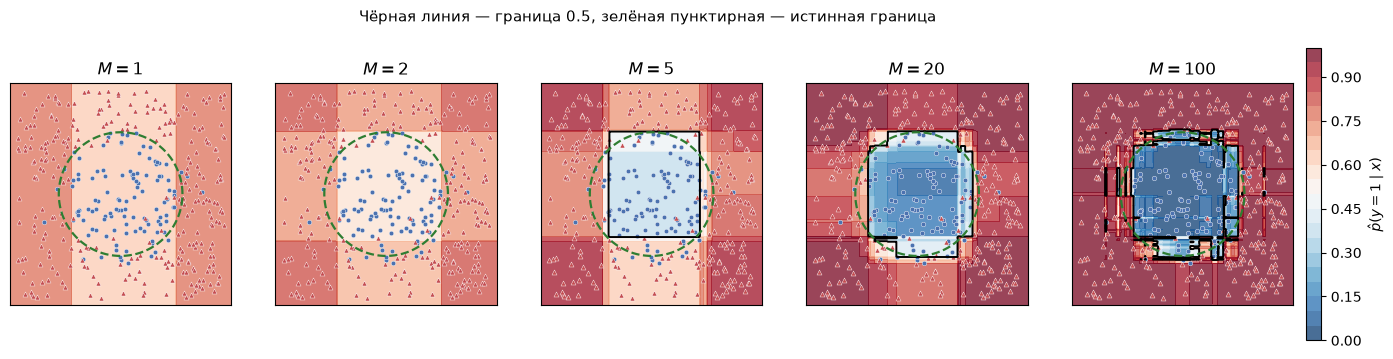

M=   1:  минимальная предсказанная вероятность 0.6258, максимальная 0.7906
M=   2:  минимальная предсказанная вероятность 0.5621, максимальная 0.8441
M=   5:  минимальная предсказанная вероятность 0.3917, максимальная 0.9409
M=  20:  минимальная предсказанная вероятность 0.0964, максимальная 0.9980
M= 100:  минимальная предсказанная вероятность 0.0016, максимальная 1.0000


In [21]:
STEPS_C = (1, 2, 5, 20, 100)
g1 = np.linspace(-3.2, 3.2, 240)
GX, GY = np.meshgrid(g1, g1)
G = np.c_[GX.ravel(), GY.ravel()]

path_c = boost_logloss(X_c, y_c, G, depth=2, lr=0.3, M=max(STEPS_C), newton=True)

fig, axes = plt.subplots(1, len(STEPS_C), figsize=(17, 3.8))
theta = np.linspace(0, 2 * np.pi, 300)
for ax, m in zip(axes, STEPS_C):
    P = sigmoid(path_c[m - 1]).reshape(GX.shape)
    cs = ax.contourf(GX, GY, P, levels=np.linspace(0, 1, 21), cmap="RdBu_r", alpha=0.75)
    ax.contour(GX, GY, P, levels=[0.5], colors="black", linewidths=1.4)
    ax.plot(np.sqrt(3.2) * np.cos(theta), np.sqrt(3.2) * np.sin(theta),
            color="#2E7D32", lw=1.6, ls="--")
    ax.scatter(X_c[y_c == 0, 0], X_c[y_c == 0, 1], s=11, c="#4C72B0",
               edgecolor="white", lw=0.3, marker="o")
    ax.scatter(X_c[y_c == 1, 0], X_c[y_c == 1, 1], s=13, c="#C44E52",
               edgecolor="white", lw=0.3, marker="^")
    ax.set_title(f"$M = {m}$")
    ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect("equal")
fig.colorbar(cs, ax=axes, fraction=0.016, pad=0.01, label="$\\hat{p}(y=1 \\mid x)$")
fig.suptitle("Чёрная линия — граница 0.5, зелёная пунктирная — истинная граница", fontsize=11)
plt.show()

for m in STEPS_C:
    p = sigmoid(path_c[m - 1])
    print(f"M={m:4d}:  минимальная предсказанная вероятность {p.min():.4f}, "
          f"максимальная {p.max():.4f}")

Граница собирается из прямоугольников: к $M = 20$ форма узнаваема, к $M = 100$
появились выступы вокруг отдельных объектов — то же переобучение, что и в разделе 2.2.

Диапазон предсказанных вероятностей расширяется с каждой итерацией:
логит складывается из всё большего числа слагаемых, и сигмоида насыщается. Поэтому
переобученный бустинг не просто чаще ошибается — он ошибается **уверенно**.

## 4. Бустинг на Титанике

### 4.1 Число деревьев

Чтобы не трогать тест, выделим внутри обучающей части временную валидационную
выборку — только для графика. `staged_decision_function` отдаёт предсказания после
каждой итерации, поэтому вся кривая получается за одно обучение.

временное разбиение: 534 / 178
eta=0.30: максимум val AUC 0.9130 на M= 12  |  val AUC при M=600 0.8689  |  train logloss при M=600 0.0281
eta=0.10: максимум val AUC 0.9118 на M= 60  |  val AUC при M=600 0.8753  |  train logloss при M=600 0.0737
eta=0.05: максимум val AUC 0.9105 на M= 67  |  val AUC при M=600 0.8996  |  train logloss при M=600 0.1492


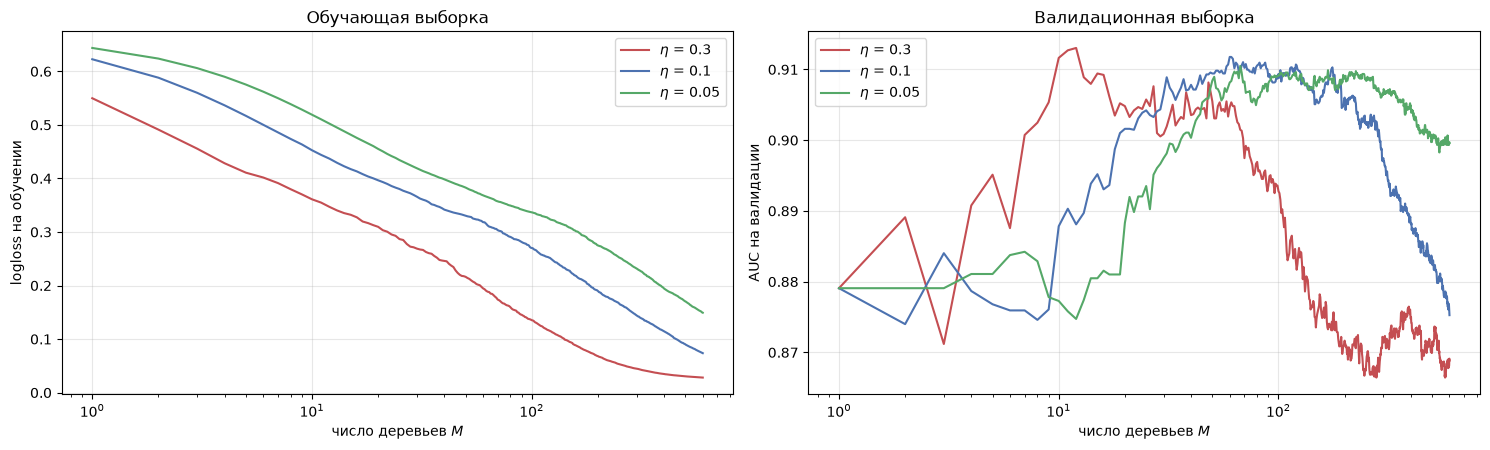

In [22]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25,
    random_state=RANDOM_STATE, stratify=y_train_full)

prep_tmp = make_prep().fit(X_train)
A, V = prep_tmp.transform(X_train), prep_tmp.transform(X_val)
print(f"временное разбиение: {len(X_train)} / {len(X_val)}")

M_T = 600
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.6))
for lr, color in zip((0.3, 0.1, 0.05), ("#C44E52", "#4C72B0", "#55A868")):
    g = GradientBoostingClassifier(n_estimators=M_T, learning_rate=lr, max_depth=3,
                                   random_state=RANDOM_STATE).fit(A, y_train)
    tr_ll = np.array([log_loss(y_train, sigmoid(s)) for s in g.staged_decision_function(A)])
    va_auc = np.array([roc_auc_score(y_val, s) for s in g.staged_decision_function(V)])
    ax1.plot(np.arange(1, M_T + 1), tr_ll, color=color, lw=1.5, label=f"$\\eta$ = {lr}")
    ax2.plot(np.arange(1, M_T + 1), va_auc, color=color, lw=1.5, label=f"$\\eta$ = {lr}")
    print(f"eta={lr:4.2f}: максимум val AUC {va_auc.max():.4f} на M={int(va_auc.argmax())+1:3d}"
          f"  |  val AUC при M={M_T} {va_auc[-1]:.4f}  |  train logloss при M={M_T} {tr_ll[-1]:.4f}")

ax1.set_xlabel("число деревьев $M$"); ax1.set_ylabel("logloss на обучении")
ax1.set_title("Обучающая выборка"); ax1.set_xscale("log"); ax1.legend()
ax2.set_xlabel("число деревьев $M$"); ax2.set_ylabel("AUC на валидации")
ax2.set_title("Валидационная выборка"); ax2.set_xscale("log"); ax2.legend()
plt.tight_layout(); plt.show()

Та же картина, что на синтетике: слева потеря на обучении падает почти до нуля,
справа качество на валидации проходит максимум и снижается — причём очень рано,
на десятках деревьев. Видна и связь $\eta$ с $M$: чем больше темп, тем раньше
максимум.

### 4.2 Ранняя остановка

Перебирать $M$ по сетке расточительно: композиция и так строится по одному дереву,
поэтому достаточно следить за качеством по ходу и остановиться, когда оно перестанет
расти. В `sklearn` это `n_iter_no_change` вместе с `validation_fraction`.

In [23]:
es = GradientBoostingClassifier(n_estimators=2000, learning_rate=0.1, max_depth=3,
                                validation_fraction=0.2, n_iter_no_change=20,
                                random_state=RANDOM_STATE).fit(A, y_train)
print(f"запрошено 2000 деревьев, построено {es.n_estimators_}")

запрошено 2000 деревьев, построено 44


Ранняя остановка решает только выбор $M$ и делает это по одному разбиению.
Остальные параметры всё равно приходится перебирать, поэтому ниже подберём $M$
вместе с ними по кросс-валидации.

### 4.3 Подбор гиперпараметров

Перебираем темп обучения, глубину базового дерева и число итераций совместно.

In [24]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__learning_rate": [0.3, 0.1, 0.05, 0.02],
    "model__max_depth": [1, 2, 3],
    "model__n_estimators": [50, 100, 200, 400],
}

gs = GridSearchCV(make_pipe(GradientBoostingClassifier(random_state=RANDOM_STATE)),
                  param_grid, scoring="roc_auc", cv=skf, n_jobs=-1)
gs.fit(X_train_full, y_train_full)

res = pd.DataFrame(gs.cv_results_)
res["eta"] = res["param_model__learning_rate"].astype(float)
res["depth"] = res["param_model__max_depth"].astype(int)
res["M"] = res["param_model__n_estimators"].astype(int)

print(f"перебрано конфигураций: {len(res)}")
print(f"лучшая: {({k.split('__')[1]: v for k, v in gs.best_params_.items()})}, "
      f"CV AUC {gs.best_score_:.4f}")

перебрано конфигураций: 48
лучшая: {'learning_rate': 0.3, 'max_depth': 2, 'n_estimators': 100}, CV AUC 0.8881


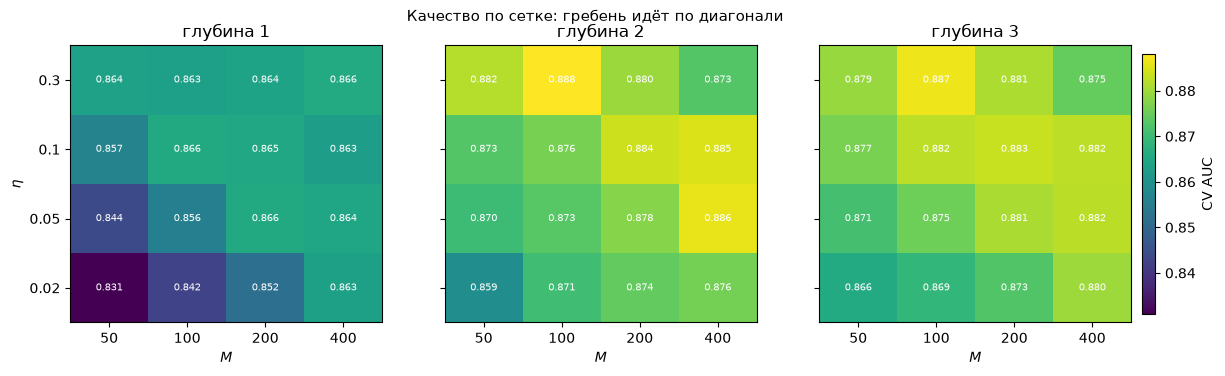

In [25]:
depths_grid = sorted(res.depth.unique())
fig, axes = plt.subplots(1, len(depths_grid), figsize=(14, 3.6), sharey=True)
vmin, vmax = res.mean_test_score.min(), res.mean_test_score.max()
for ax, d in zip(axes, depths_grid):
    piv = res[res.depth == d].pivot_table(index="eta", columns="M", values="mean_test_score")
    piv = piv.sort_index(ascending=False)
    im = ax.imshow(piv.values, cmap="viridis", vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(piv.columns)), piv.columns)
    ax.set_yticks(range(len(piv.index)), piv.index)
    ax.set_xlabel("$M$"); ax.set_title(f"глубина {d}")
    ax.grid(False)
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            ax.text(j, i, f"{piv.values[i, j]:.3f}", ha="center", va="center",
                    fontsize=7, color="white")
axes[0].set_ylabel("$\\eta$")
fig.colorbar(im, ax=axes, fraction=0.012, pad=0.01, label="CV AUC")
fig.suptitle("Качество по сетке: гребень идёт по диагонали", fontsize=11)
plt.show()

Тут заметим, что эта визуализация доступна только при подборе по небольшому числу гиперпараметров. 

Хорошие значения лежат примерно по диагонали.
Углы плохи по разным причинам — где-то композиция не успевает обучиться, где-то
переобучается.

Теперь важная оговорка про сам максимум.

In [26]:
best = res.mean_test_score.max()
se = res.loc[res.mean_test_score.idxmax(), "std_test_score"] / np.sqrt(skf.get_n_splits())
within = res[res.mean_test_score >= best - se]

print(f"лучшее CV AUC {best:.4f}, стандартная ошибка {se:.4f}")
print(f"конфигураций в пределах одной стандартной ошибки: {len(within)} из {len(res)}")
print()
print(within.sort_values("mean_test_score", ascending=False)
      .head(6)[["eta", "depth", "M", "mean_test_score", "std_test_score"]].to_string(index=False))

лучшее CV AUC 0.8881, стандартная ошибка 0.0086
конфигураций в пределах одной стандартной ошибки: 14 из 48

 eta  depth   M  mean_test_score  std_test_score
0.30      2 100           0.8881          0.0193
0.30      3 100           0.8867          0.0139
0.05      2 400           0.8863          0.0207
0.10      2 400           0.8851          0.0203
0.10      2 200           0.8838          0.0223
0.10      3 200           0.8834          0.0202


Заметная часть сетки статистически неотличима от максимума. В такой ситуации можно взять самую простую конфигурацию, то есть
неглубокое дерево с малым темпом.

In [27]:
# порядок предпочтения: сначала минимальная глубина, затем минимальный темп,
# затем минимальное число деревьев — выбор получается однозначным
chosen = within.sort_values(["depth", "eta", "M"]).iloc[0]
GB_PARAMS = dict(learning_rate=float(chosen.eta), max_depth=int(chosen.depth),
                 n_estimators=int(chosen.M))
print("выбрано:", GB_PARAMS)
print(f"CV AUC {chosen.mean_test_score:.4f} против {best:.4f} у максимума сетки")

выбрано: {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 400}
CV AUC 0.8863 против 0.8881 у максимума сетки


### 4.4 Важность признаков

Две меры, как и у леса: встроенная и перестановочная. Вторую считаем на валидационной
части, не на обучающей и не на тесте.

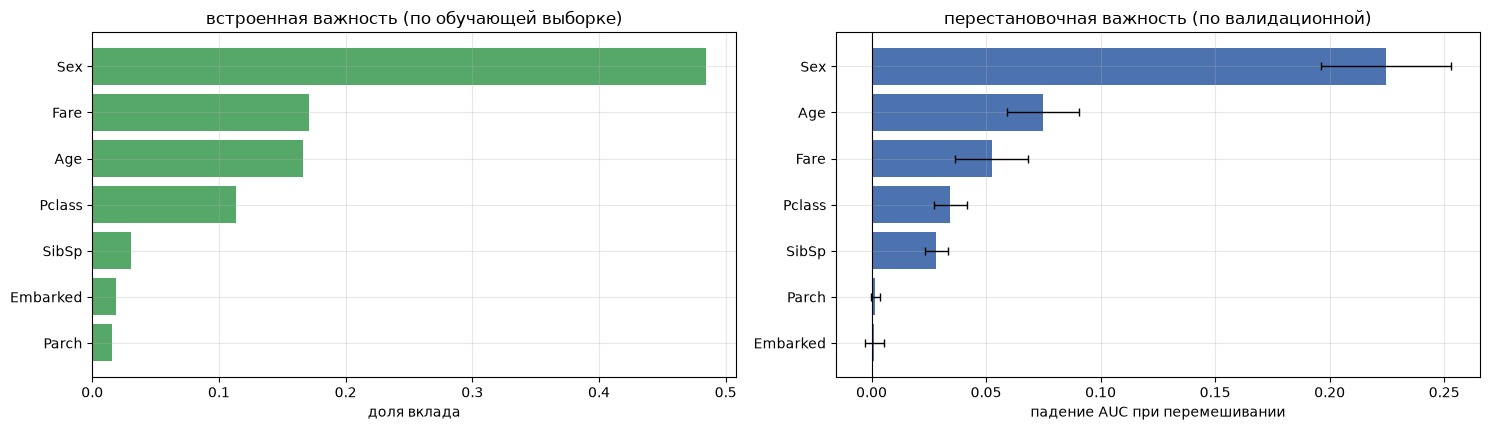

          встроенная  перестановочная  разброс
Sex           0.4843           0.2245   0.0283
Age           0.1665           0.0748   0.0157
Fare          0.1709           0.0525   0.0160
Pclass        0.1135           0.0344   0.0072
SibSp         0.0306           0.0283   0.0050
Parch         0.0157           0.0017   0.0020
Embarked      0.0185           0.0013   0.0041


In [28]:
from sklearn.inspection import permutation_importance

gb_fit = make_pipe(GradientBoostingClassifier(random_state=RANDOM_STATE, **GB_PARAMS))
gb_fit.fit(X_train, y_train)

raw_imp = pd.Series(gb_fit.named_steps["model"].feature_importances_,
                    index=gb_fit.named_steps["prep"].get_feature_names_out())


def to_original(name: str) -> str:
    """cat__Pclass_3 -> Pclass, num__Age -> Age: сводим one-hot обратно к колонке."""
    stem = name.split("__", 1)[1]
    for c in CAT:
        if stem.startswith(c + "_"):
            return c
    return stem


imp = raw_imp.groupby(to_original).sum()

pi = permutation_importance(gb_fit, X_val, y_val, n_repeats=30, scoring="roc_auc",
                            random_state=RANDOM_STATE, n_jobs=-1)
perm = pd.DataFrame({"важность": pi.importances_mean, "разброс": pi.importances_std},
                    index=X_val.columns).sort_values("важность", ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.4))
s = imp.sort_values()
ax1.barh(s.index, s.values, color="#55A868")
ax1.set_title("встроенная важность (по обучающей выборке)")
ax1.set_xlabel("доля вклада")

o = perm.index[::-1]
ax2.barh(o, perm.loc[o, "важность"], xerr=perm.loc[o, "разброс"], color="#4C72B0",
         error_kw={"lw": 1, "capsize": 3})
ax2.axvline(0, color="black", lw=0.8)
ax2.set_title("перестановочная важность (по валидационной)")
ax2.set_xlabel("падение AUC при перемешивании")
plt.tight_layout(); plt.show()

print(pd.DataFrame({"встроенная": imp, "перестановочная": perm["важность"],
                    "разброс": perm["разброс"]}).sort_values(
                        "перестановочная", ascending=False).round(4).to_string())

`Sex` на первом месте по обеим мерам: пол объясняет выживание лучше всего остального
вместе взятого — шлюпки заполняли женщинами и детьми.

Дальше начинаются расхождения. `Age` и `Fare` меняются местами: встроенная мера
ставит выше `Fare`, перестановочная — `Age`.

Встроенная важность отдаёт `Parch` и `Embarked` по полтора-два
процента вклада, тогда как по перестановкам их эффект меньше собственного разброса:
перемешивание этих признаков качество не меняет. Причина в том, что встроенная мера
награждает признак за каждое участие в разбиении — в том числе за разбиения,
подгонявшие шум. Перестановочная отвечает на другой вопрос: нужен ли признак модели
*при наличии остальных*.

## 5. Сравнение моделей

Собираем всё вместе. Схема прежняя: гиперпараметры
каждой модели подбираются кросс-валидацией на обучающей части, тест используется
один раз.

In [29]:
from sklearn.neighbors import KNeighborsClassifier

searches = {
    "логистическая регрессия": (LogisticRegression(max_iter=5000), True,
                                {"model__C": [0.01, 0.1, 0.3, 1, 3, 10, 100]}),
    "kNN": (KNeighborsClassifier(), True,
            {"model__n_neighbors": [1, 3, 5, 10, 15, 20, 30, 50],
             "model__weights": ["uniform", "distance"]}),
    "решающее дерево": (DecisionTreeClassifier(random_state=RANDOM_STATE), False,
                        {"model__max_depth": [2, 3, 4, 5, 6, 8, None],
                         "model__min_samples_leaf": [1, 5, 10, 20, 40]}),
    "случайный лес": (RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE,
                                             n_jobs=-1), False,
                      {"model__max_features": [1, 2, 3, 4, 6, 9],
                       "model__min_samples_leaf": [1, 3, 5]}),
}

tuned = {}
for name, (model, scale, grid) in searches.items():
    s = GridSearchCV(make_pipe(model, scale), grid, scoring="roc_auc", cv=skf, n_jobs=-1)
    s.fit(X_train_full, y_train_full)
    tuned[name] = s.best_estimator_
    print(f"{name:24s} {({k.split('__')[1]: v for k, v in s.best_params_.items()})}"
          f"  CV AUC {s.best_score_:.4f}")

tuned["градиентный бустинг"] = make_pipe(
    GradientBoostingClassifier(random_state=RANDOM_STATE, **GB_PARAMS))
print(f"{'градиентный бустинг':24s} {GB_PARAMS} CV AUC {chosen.mean_test_score:.4f}")

логистическая регрессия  {'C': 100}  CV AUC 0.8530
kNN                      {'n_neighbors': 15, 'weights': 'uniform'}  CV AUC 0.8473
решающее дерево          {'max_depth': 4, 'min_samples_leaf': 20}  CV AUC 0.8465
случайный лес            {'max_features': 2, 'min_samples_leaf': 3}  CV AUC 0.8779
градиентный бустинг      {'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 400} CV AUC 0.8863


Тест маленький — 179 объектов. Чтобы понять, какие различия на нём вообще можно
обсуждать, посчитаем бутстрэп-интервал: много раз берём выборку из теста
с возвращением и смотрим на разброс AUC.

In [30]:
rows = [{"модель": "константа", "CV AUC": np.nan, "CV std": np.nan, "test AUC": 0.5,
         "test accuracy": accuracy_score(y_test, np.zeros(len(y_test)))}]
for name, model in tuned.items():
    auc = cv_score(model)
    model.fit(X_train_full, y_train_full)
    p = model.predict_proba(X_test)[:, 1]
    rows.append({"модель": name, "CV AUC": auc.mean(), "CV std": auc.std(),
                 "test AUC": roc_auc_score(y_test, p), "test accuracy": accuracy_score(y_test, p > 0.5)})

summary = pd.DataFrame(rows).set_index("модель")
summary.round(4)

,CV AUC,CV std,test AUC,test accuracy
модель,,,,
константа,NaN,NaN,0.5000,0.6145
логистическая регрессия,0.8530,0.0211,0.8427,0.8045
kNN,0.8473,0.0319,0.8355,0.7933
решающее дерево,0.8465,0.0275,0.7926,0.7821
случайный лес,0.8779,0.0196,0.8391,0.7989
градиентный бустинг,0.8863,0.0207,0.8091,0.7933


Почему здесь побеждает лес.

Бустинг уменьшает смещение — это его сильная сторона там, где смещение и есть
главная составляющая ошибки. Но у Титаника 712 обучающих объектов, семь признаков
и очень высокий неустранимый шум: в разделе 1.3 мы видели пассажиров, совпадающих
по всем признакам и имеющих разный исход.

Второе: бустинг требует согласованного подбора трёх параметров, и на маленькой
выборке сам подбор становится источником ошибки.

Отсюда правило: преимущество бустинга растёт с размером выборки. На десятках и сотнях
тысяч объектов он обычно и оказывается сильнейшим методом для табличных данных —
поэтому XGBoost, LightGBM и CatBoost так распространены. Переносить напрямую этот опыт
на сотни объектов без проверки нельзя.